# A4 - LLM Agreement

This notebook compares the basic and enhanced LLM codes with the human codes, at the turn level.

- **Test sample:** OBS_26-0498, segments c and d. Both LLM runs and both human coders coded these lines, and they were not used to develop the codebook.
- **Development check:** OBS_26-0515, segments a and b. These were used to calibrate the codebook, so they are reported only against the adjudicated codes and are not a clean test.

All inputs are code-only files already in the repository (`results/analysis_table.csv` and `Data/human_coding/`), so the notebook runs without the transcripts. Run it from the top of the repository. Outputs go to `results/llm_agreement/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the turn rule and kappa from the human IRR script.
sys.path.append("analysis")
from irr_semantic import build_turns, cohens_kappa

RESULTS_DIR = Path("results")
CODING_DIR = Path("Data/human_coding")
OUTPUT_DIR = RESULTS_DIR / "llm_agreement"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TEST = "OBS_26-0498"
DEVELOPMENT = "OBS_26-0515"
SAMPLE_LABELS = {TEST: "Test: OBS_26-0498 c-d", DEVELOPMENT: "Development: OBS_26-0515 a-b"}

SELF_LEVELS = ["fully detailed", "some detail", "wrong detail", "no detail"]
OTHER_LEVELS = ["high", "medium", "low"]
CODED_WHOSE = ["self", "other"]
NOT_CODED = {"", "n/a", "unclear", "unclear / not coded"}

## 1. Load the codes

`analysis_table.csv` has one row per transcript line, with the adjudicated human codes and both LLM outputs aligned on the same `row` IDs.

Adult lines (`is_adult`) are dropped before anything is compared. For the two individual coders on the test sample we use the normalized files written by `analysis/irr_semantic.py`. Normalization applies codebook rules that one coder had not yet applied (for example, an answer to the teacher is Self), so rule differences are not counted as disagreements. This keeps the LLM comparisons consistent with the human IRR. The LLM outputs are not normalized, because they are what we are evaluating.

In [2]:
table = pd.read_csv(RESULTS_DIR / "analysis_table.csv", keep_default_na=False, dtype=str)


def read_codes(path):
    return pd.read_csv(path, keep_default_na=False, dtype=str)


raw_coders = {
    "Vishal": read_codes(CODING_DIR / "codes_OBS_26-0498_Vishal.csv"),
    "Caesar": read_codes(CODING_DIR / "humancodes_OBS_26_0498_Caesar.csv"),
}
normalized_coders = {
    name: read_codes(CODING_DIR / "normalized" / f"codes_OBS_26-0498_cd_{name}_normalized.csv")
    for name in raw_coders
}

# Keep segments c and d, which are the rows in the normalized files.
for name in raw_coders:
    rows = normalized_coders[name]["row"]
    raw_coders[name] = raw_coders[name][raw_coders[name]["row"].isin(rows)].reset_index(drop=True)
    assert list(raw_coders[name]["row"]) == list(rows)

# Adult lines are never coded, so drop them before building turns.
adult_rows = set(table.loc[(table["observation"] == TEST) & (table["is_adult"] == "True"), "row"])
for codes in [raw_coders, normalized_coders]:
    for name in codes:
        codes[name] = codes[name][~codes[name]["row"].isin(adult_rows)].reset_index(drop=True)

input_status = pd.DataFrame([
    {"observation": observation,
     "lines": len(group),
     "student lines": int((group["is_adult"] == "False").sum()),
     "adjudicated lines with a code": int((group["human_final_whose"] != "").sum())}
    for observation, group in table.groupby("observation")
])
input_status

,observation,lines,student lines,adjudicated lines with a code
0,OBS_26-0498,97,63,37
1,OBS_26-0515,151,122,88


## 2. Clean labels and build turns

Labels differ in capitalization between methods, and the enhanced prompt writes "Unclear / not coded". We lowercase every label and treat blank, N/A, Unclear, and "Unclear / not coded" as not coded.

Codes are compared by **turn**, using the same rule as the human IRR: a turn is a speaker's coded lines up to the line where the reference coder recorded a Level, within one segment. Turns always come from the **reference** (the human codes being compared against), so every rater is scored on the same units. A human rater's code for a turn is the last Whose and the last Level they gave on any line of that turn.

The enhanced prompt divides lines into its own turns (`enhanced_turn`) and writes the Level only on the last line of each, which can fall after the end of the human turn. Its Level for a reference turn is therefore the Level of the enhanced turn that contains the reference turn's last line.

The basic prompt gives every line both an explanation label and a peer-engagement label and never says Self or Other. Following `results/README.md`, we take its explanation label on turns the reference coded Self and its engagement label on turns the reference coded Other.

In [3]:
def clean(label):
    label = str(label).strip().lower()
    return "" if label in NOT_CODED else label


def last_code(labels):
    labels = [label for label in labels if label]
    return labels[-1] if labels else ""


def segment_turns(raw):
    # build_turns runs over the whole file, so run it per segment to keep turns from crossing segments.
    turns = []
    for _, segment in raw.groupby(raw["row"].str[0], sort=False):
        segment = segment.reset_index(drop=True)
        turns += [list(segment.loc[turn, "row"]) for turn in build_turns(segment)]
    return turns


def make_reference(raw, codes):
    # raw: original labels, used only to find turn boundaries; codes: the labels to compare.
    turns = segment_turns(raw)
    codes = codes.set_index("row")
    return {
        "turns": turns,
        "speaker": codes["speaker"],
        "whose": codes["whose"].map(clean),
        "level": codes["level"].map(clean),
    }


def final_codes(observation):
    lines = table[(table["observation"] == observation) & (table["is_adult"] == "False")]
    return pd.DataFrame({
        "row": lines["row"].values,
        "speaker": lines["speaker"].values,
        "whose": lines["human_final_whose"].values,
        "level": lines["human_final_level"].values,
    })


references = {
    (TEST, "Vishal"): make_reference(raw_coders["Vishal"], normalized_coders["Vishal"]),
    (TEST, "Caesar"): make_reference(raw_coders["Caesar"], normalized_coders["Caesar"]),
    (TEST, "Adjudicated"): make_reference(final_codes(TEST), final_codes(TEST)),
    (DEVELOPMENT, "Adjudicated"): make_reference(final_codes(DEVELOPMENT), final_codes(DEVELOPMENT)),
}

pd.DataFrame([
    {"observation": observation, "reference": name, "turns": len(reference["turns"])}
    for (observation, name), reference in references.items()
])

,observation,reference,turns
0,OBS_26-0498,Vishal,26
1,OBS_26-0498,Caesar,34
2,OBS_26-0498,Adjudicated,30
3,OBS_26-0515,Adjudicated,37


## 3. Score each rater on the reference turns

Each rater returns a Whose and a Level for a turn. The other human coder is included as a rater so the LLM results can be read against human-human agreement on exactly the same turns.

For each reference and rater we report:

- **Whose agreement and κ** on turns both coded Self or Other (not available for the basic prompt). We also count reference turns the rater left not coded.
- **Level agreement on all turns**: matches out of every reference turn with a Self or Other Level. The denominator is the same for every rater, so this is the fairest number for comparing the basic and enhanced prompts. A turn the rater left uncoded, or coded on the other scale, counts as a miss.
- **Level agreement and κ on comparable turns**: only turns where the rater gave a Level on the same scale (for raters with Whose, the same Whose). This matches the definition used in the human IRR.

In [4]:
def llm_lines(observation):
    lines = table[table["observation"] == observation].set_index("row")
    cleaned = {column: lines[column].map(clean) for column in
               ["basic_explanation", "basic_peer_engagement", "enhanced_whose", "enhanced_level"]}
    cleaned["enhanced_turn"] = lines["enhanced_turn"]
    cleaned["enhanced_turn_level"] = (
        cleaned["enhanced_level"].groupby(lines["enhanced_turn"]).agg(last_code)
    )
    return cleaned


def rate_enhanced(lines, rows, reference_whose):
    whose = last_code(lines["enhanced_whose"][rows])
    turn_ids = [turn for turn in lines["enhanced_turn"][rows] if turn]
    level = lines["enhanced_turn_level"][turn_ids[-1]] if turn_ids else ""
    return (whose, level)


def rate_basic(lines, rows, reference_whose):
    column = "basic_explanation" if reference_whose == "self" else "basic_peer_engagement"
    return (None, last_code(lines[column][rows]))


def human_rater(name):
    codes = normalized_coders[name].set_index("row")
    whose, level = codes["whose"].map(clean), codes["level"].map(clean)
    return lambda lines, rows, reference_whose: (last_code(whose[rows]), last_code(level[rows]))


def compare(observation, reference_name, rater_name, rater):
    reference = references[(observation, reference_name)]
    lines = llm_lines(observation)
    records = []
    for rows in reference["turns"]:
        reference_whose = last_code(reference["whose"][rows])
        reference_level = last_code(reference["level"][rows])
        rater_whose, rater_level = rater(lines, rows, reference_whose)
        records.append({
            "observation": observation,
            "reference": reference_name,
            "rater": rater_name,
            "turn": rows[0] if len(rows) == 1 else f"{rows[0]}-{rows[-1]}",
            "rows": " ".join(rows),
            "speaker": reference["speaker"][rows[-1]],
            "reference_whose": reference_whose,
            "reference_level": reference_level,
            "rater_whose": rater_whose,
            "rater_level": rater_level,
        })
    return pd.DataFrame(records)


comparisons = [
    ("Vishal", "Basic LLM", rate_basic),
    ("Vishal", "Enhanced LLM", rate_enhanced),
    ("Vishal", "Caesar", human_rater("Caesar")),
    ("Caesar", "Basic LLM", rate_basic),
    ("Caesar", "Enhanced LLM", rate_enhanced),
    ("Caesar", "Vishal", human_rater("Vishal")),
    ("Adjudicated", "Basic LLM", rate_basic),
    ("Adjudicated", "Enhanced LLM", rate_enhanced),
]

turn_table = pd.concat(
    [compare(TEST, reference, rater_name, rater) for reference, rater_name, rater in comparisons]
    + [compare(DEVELOPMENT, "Adjudicated", rater_name, rater)
       for rater_name, rater in [("Basic LLM", rate_basic), ("Enhanced LLM", rate_enhanced)]],
    ignore_index=True,
)
turn_table.to_csv(OUTPUT_DIR / "turn_comparison.csv", index=False)
turn_table.head()

,observation,reference,rater,turn,rows,speaker,reference_whose,reference_level,rater_whose,rater_level
0,OBS_26-0498,Vishal,Basic LLM,c5,c5,Other,self,some detail,None,some detail
1,OBS_26-0498,Vishal,Basic LLM,c10,c10,Gregorio,self,some detail,None,some detail
2,OBS_26-0498,Vishal,Basic LLM,c11,c11,Other,other,medium,None,high
3,OBS_26-0498,Vishal,Basic LLM,c12-c13,c12 c13,Gregorio,other,high,None,high
4,OBS_26-0498,Vishal,Basic LLM,c14,c14,Miguel,other,high,None,high


In [5]:
def summarize(turns):
    has_whose = turns["rater_whose"].notna().all()
    coded = turns[turns["reference_whose"].isin(CODED_WHOSE)]
    with_level = coded[coded["reference_level"] != ""]
    summary = {"reference turns": len(turns), "coded reference turns": len(coded)}

    if has_whose:
        both = coded[coded["rater_whose"].isin(CODED_WHOSE)]
        summary.update({
            "whose n": len(both),
            "whose matches": int((both["reference_whose"] == both["rater_whose"]).sum()),
            "whose kappa": cohens_kappa(both["reference_whose"], both["rater_whose"]),
            "rater left not coded": len(coded) - len(both),
        })

    summary.update({
        "level all n": len(with_level),
        "level all matches": int((with_level["reference_level"] == with_level["rater_level"]).sum()),
    })

    comparable = with_level[with_level["rater_level"] != ""]
    if has_whose:
        comparable = comparable[comparable["reference_whose"] == comparable["rater_whose"]]
    summary.update({
        "level n": len(comparable),
        "level matches": int((comparable["reference_level"] == comparable["rater_level"]).sum()),
        "level kappa": cohens_kappa(comparable["reference_level"], comparable["rater_level"]),
    })
    return summary


# Build the rows directly: the basic prompt has no Whose columns.
summary = pd.DataFrame([
    {"observation": observation, "reference": reference, "rater": rater, **summarize(turns)}
    for (observation, reference, rater), turns
    in turn_table.groupby(["observation", "reference", "rater"], sort=False)
])

for prefix in ["whose", "level all", "level"]:
    summary[f"{prefix} agreement"] = summary[f"{prefix} matches"] / summary[f"{prefix} n"]

summary.to_csv(OUTPUT_DIR / "agreement_summary.csv", index=False)
summary

,observation,reference,rater,reference turns,coded reference turns,level all n,level all matches,level n,level matches,level kappa,whose n,whose matches,whose kappa,rater left not coded,whose agreement,level all agreement,level agreement
0,OBS_26-0498,Vishal,Basic LLM,26,26,26,15,26,15,0.481884,NaN,NaN,NaN,NaN,NaN,0.576923,0.576923
1,OBS_26-0498,Vishal,Enhanced LLM,26,26,26,11,19,11,0.503268,25.0,19.0,0.522293,1.0,0.760000,0.423077,0.578947
2,OBS_26-0498,Vishal,Caesar,26,26,26,11,19,11,0.488215,24.0,19.0,0.552239,2.0,0.791667,0.423077,0.578947
3,OBS_26-0498,Caesar,Basic LLM,34,28,27,15,27,15,0.439446,NaN,NaN,NaN,NaN,NaN,0.555556,0.555556
4,OBS_26-0498,Caesar,Enhanced LLM,34,28,27,12,18,12,0.584615,24.0,19.0,0.565217,4.0,0.791667,0.444444,0.666667
5,OBS_26-0498,Caesar,Vishal,34,28,27,11,19,11,0.488215,26.0,20.0,0.503185,2.0,0.769231,0.407407,0.578947
6,OBS_26-0498,Adjudicated,Basic LLM,30,30,29,10,27,10,0.251223,NaN,NaN,NaN,NaN,NaN,0.344828,0.370370
7,OBS_26-0498,Adjudicated,Enhanced LLM,30,30,29,11,22,11,0.414044,27.0,23.0,0.704918,3.0,0.851852,0.379310,0.500000
8,OBS_26-0515,Adjudicated,Basic LLM,37,37,34,11,31,11,0.257485,NaN,NaN,NaN,NaN,NaN,0.323529,0.354839
9,OBS_26-0515,Adjudicated,Enhanced LLM,37,37,34,13,25,13,0.416342,33.0,27.0,0.608696,4.0,0.818182,0.382353,0.520000


**Check against the human IRR.** Scoring Caesar on Vishal's turns should reproduce `Data/human_coding/normalized/irr_summary_OBS_26-0498_cd.csv`.

In [6]:
irr = pd.read_csv(CODING_DIR / "normalized" / "irr_summary_OBS_26-0498_cd.csv")
human_pair = summary[(summary["reference"] == "Vishal") & (summary["rater"] == "Caesar")].iloc[0]

assert human_pair["whose n"] == irr.loc[0, "units"]
assert np.isclose(human_pair["whose kappa"], irr.loc[0, "kappa"], atol=0.001)
assert human_pair["level n"] == irr.loc[1, "units"]
assert np.isclose(human_pair["level kappa"], irr.loc[1, "kappa"], atol=0.001)
print("Matches the human IRR summary.")

Matches the human IRR summary.


## 4. Agreement table

A readable version of the summary, saved as CSV and as an image. "k/n" gives matches over the denominator.

In [7]:
def fraction(matches, n):
    return "" if pd.isna(n) else f"{int(matches)}/{int(n)} ({matches / n:.0%})" if n else "0/0"


def kappa_text(value):
    return "" if pd.isna(value) else f"{value:.2f}"


agreement_table = pd.DataFrame({
    "Sample": summary["observation"].map(SAMPLE_LABELS),
    "Reference": summary["reference"],
    "Rater": summary["rater"],
    "Whose agreement": [fraction(m, n) if not pd.isna(n) else "n/a (no Whose)"
                        for m, n in zip(summary["whose matches"], summary["whose n"])],
    "Whose κ": summary["whose kappa"].map(kappa_text),
    "Not coded by rater": summary["rater left not coded"].map(lambda x: "" if pd.isna(x) else int(x)),
    "Level, all turns": [fraction(m, n) for m, n in zip(summary["level all matches"], summary["level all n"])],
    "Level, comparable turns": [fraction(m, n) for m, n in zip(summary["level matches"], summary["level n"])],
    "Level κ": summary["level kappa"].map(kappa_text),
})
agreement_table.to_csv(OUTPUT_DIR / "agreement_table.csv", index=False)
agreement_table

,Sample,Reference,Rater,Whose agreement,Whose κ,Not coded by rater,"Level, all turns","Level, comparable turns",Level κ
0,Test: OBS_26-0498 c-d,Vishal,Basic LLM,n/a (no Whose),,,15/26 (58%),15/26 (58%),0.48
1,Test: OBS_26-0498 c-d,Vishal,Enhanced LLM,19/25 (76%),0.52,1,11/26 (42%),11/19 (58%),0.50
2,Test: OBS_26-0498 c-d,Vishal,Caesar,19/24 (79%),0.55,2,11/26 (42%),11/19 (58%),0.49
3,Test: OBS_26-0498 c-d,Caesar,Basic LLM,n/a (no Whose),,,15/27 (56%),15/27 (56%),0.44
4,Test: OBS_26-0498 c-d,Caesar,Enhanced LLM,19/24 (79%),0.57,4,12/27 (44%),12/18 (67%),0.58
5,Test: OBS_26-0498 c-d,Caesar,Vishal,20/26 (77%),0.50,2,11/27 (41%),11/19 (58%),0.49
6,Test: OBS_26-0498 c-d,Adjudicated,Basic LLM,n/a (no Whose),,,10/29 (34%),10/27 (37%),0.25
7,Test: OBS_26-0498 c-d,Adjudicated,Enhanced LLM,23/27 (85%),0.70,3,11/29 (38%),11/22 (50%),0.41
8,Development: OBS_26-0515 a-b,Adjudicated,Basic LLM,n/a (no Whose),,,11/34 (32%),11/31 (35%),0.26
9,Development: OBS_26-0515 a-b,Adjudicated,Enhanced LLM,27/33 (82%),0.61,4,13/34 (38%),13/25 (52%),0.42


In [8]:
def save_table_image(frame, path, title, font_size=9):
    figure, axis = plt.subplots(figsize=(4, 0.3 * (len(frame) + 2)))
    axis.axis("off")
    shown = axis.table(
        cellText=frame.astype(str).values,
        colLabels=frame.columns,
        cellLoc="left",
        colLoc="left",
        loc="upper left",
    )
    shown.auto_set_font_size(False)
    shown.set_fontsize(font_size)
    shown.auto_set_column_width(list(range(frame.shape[1])))
    shown.scale(1, 1.4)
    for (row, column), cell in shown.get_celld().items():
        cell.set_edgecolor("#d0d0d0")
        if row == 0:
            cell.set_facecolor("#eef2f7")
            cell.set_text_props(weight="bold")
    axis.set_title(title, loc="left", fontsize=11, weight="bold")
    figure.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(figure)


save_table_image(
    agreement_table,
    OUTPUT_DIR / "agreement_table.png",
    "Turn-level agreement between LLM and human codes",
)

## 5. Agreement bars

Test sample only. Each group is one human reference. The other human coder is shown as a benchmark: an LLM bar near the human bar agrees with that reference about as well as the other person did.

- **Whose** is computed on turns both coded Self or Other; the basic prompt has no Whose label.
- **Level** uses all reference turns with a Level, so the denominator is the same for every rater in a group.

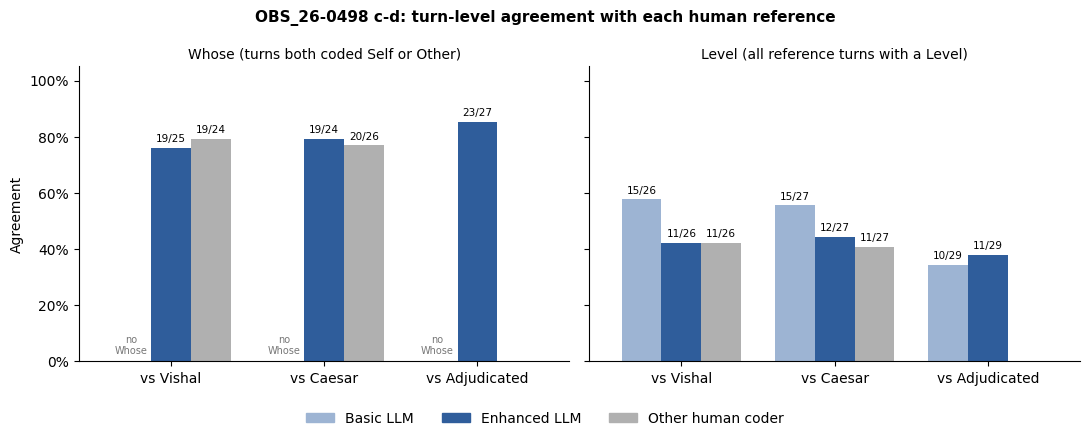

In [9]:
RATER_ORDER = ["Basic LLM", "Enhanced LLM", "Other human coder"]
RATER_COLORS = {"Basic LLM": "#9db4d3", "Enhanced LLM": "#2f5d9b", "Other human coder": "#b0b0b0"}
REFERENCE_ORDER = ["Vishal", "Caesar", "Adjudicated"]

test_summary = summary[summary["observation"] == TEST].copy()
test_summary["rater group"] = np.where(
    test_summary["rater"].isin(["Vishal", "Caesar"]), "Other human coder", test_summary["rater"]
)

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
panels = [("whose", "Whose (turns both coded Self or Other)"),
          ("level all", "Level (all reference turns with a Level)")]
width = 0.26

for axis, (prefix, title) in zip(axes, panels):
    for offset, rater in enumerate(RATER_ORDER):
        for position, reference in enumerate(REFERENCE_ORDER):
            match = test_summary[(test_summary["reference"] == reference)
                                 & (test_summary["rater group"] == rater)]
            x = position + (offset - 1) * width
            if match.empty or pd.isna(match.iloc[0][f"{prefix} n"]):
                if not match.empty:
                    axis.text(x, 0.02, "no\nWhose", ha="center", va="bottom", fontsize=7, color="#777777")
                continue
            row = match.iloc[0]
            axis.bar(x, row[f"{prefix} agreement"], width, color=RATER_COLORS[rater],
                     label=rater if position == 0 or prefix == "level all" else None)
            axis.text(x, row[f"{prefix} agreement"] + 0.015,
                      f"{int(row[f'{prefix} matches'])}/{int(row[f'{prefix} n'])}",
                      ha="center", va="bottom", fontsize=7.5)
    axis.set_xlim(-0.6, len(REFERENCE_ORDER) - 0.4)
    axis.set_xticks(range(len(REFERENCE_ORDER)))
    axis.set_xticklabels([f"vs {reference}" for reference in REFERENCE_ORDER])
    axis.set_title(title, fontsize=10)
    axis.set_ylim(0, 1.05)
    axis.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    axis.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Agreement")
handles = [plt.Rectangle((0, 0), 1, 1, color=RATER_COLORS[rater]) for rater in RATER_ORDER]
figure.legend(handles, RATER_ORDER, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
figure.suptitle("OBS_26-0498 c-d: turn-level agreement with each human reference", fontsize=11, weight="bold")
figure.tight_layout(rect=(0, 0.05, 1, 1))
figure.savefig(OUTPUT_DIR / "agreement_bars.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Confusion matrices

Test sample, against the adjudicated codes. Rows are the adjudicated label and columns are the LLM label for the same turn, so the diagonal is agreement.

- **Whose** (enhanced prompt only).
- **Level on Self turns** and **Level on Other turns**, for both prompts. "Other scale" or "Self scale" means the enhanced prompt coded the turn with the other Whose, so its Level is on the other scale.

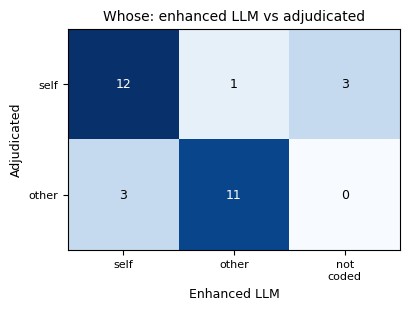

rater_value,self,other,not coded
reference_value,,,
self,12,1,3
other,3,11,0


In [10]:
def confusion(turns, row_labels, column_labels, column_map=lambda label: label):
    columns = turns["rater_value"].map(column_map)
    counts = pd.crosstab(turns["reference_value"], columns)
    return counts.reindex(index=row_labels, columns=column_labels, fill_value=0)


def plot_confusion(axis, counts, title, xlabel, ylabel):
    values = counts.values
    axis.imshow(values, cmap="Blues", vmin=0, vmax=max(values.max(), 1))
    for (i, j), value in np.ndenumerate(values):
        axis.text(j, i, value, ha="center", va="center", fontsize=9,
                  color="white" if value > values.max() / 2 else "black")
    axis.set_xticks(range(counts.shape[1]))
    axis.set_xticklabels([label.replace(" ", "\n", 1) for label in counts.columns], fontsize=8)
    axis.set_yticks(range(counts.shape[0]))
    axis.set_yticklabels(counts.index, fontsize=8)
    axis.set_xlabel(xlabel, fontsize=9)
    axis.set_ylabel(ylabel, fontsize=9)
    axis.set_title(title, fontsize=10)


adjudicated = turn_table[(turn_table["observation"] == TEST) & (turn_table["reference"] == "Adjudicated")]


def with_values(turns, column):
    turns = turns.copy()
    turns["reference_value"] = turns[f"reference_{column}"]
    turns["rater_value"] = turns[f"rater_{column}"].replace("", "not coded")
    return turns


enhanced = adjudicated[adjudicated["rater"] == "Enhanced LLM"]
whose_counts = confusion(
    with_values(enhanced[enhanced["reference_whose"].isin(CODED_WHOSE)], "whose"),
    CODED_WHOSE, CODED_WHOSE + ["not coded"],
)

figure, axis = plt.subplots(figsize=(4.2, 3.2))
plot_confusion(axis, whose_counts, "Whose: enhanced LLM vs adjudicated", "Enhanced LLM", "Adjudicated")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "confusion_whose.png", dpi=200, bbox_inches="tight")
plt.show()

whose_counts

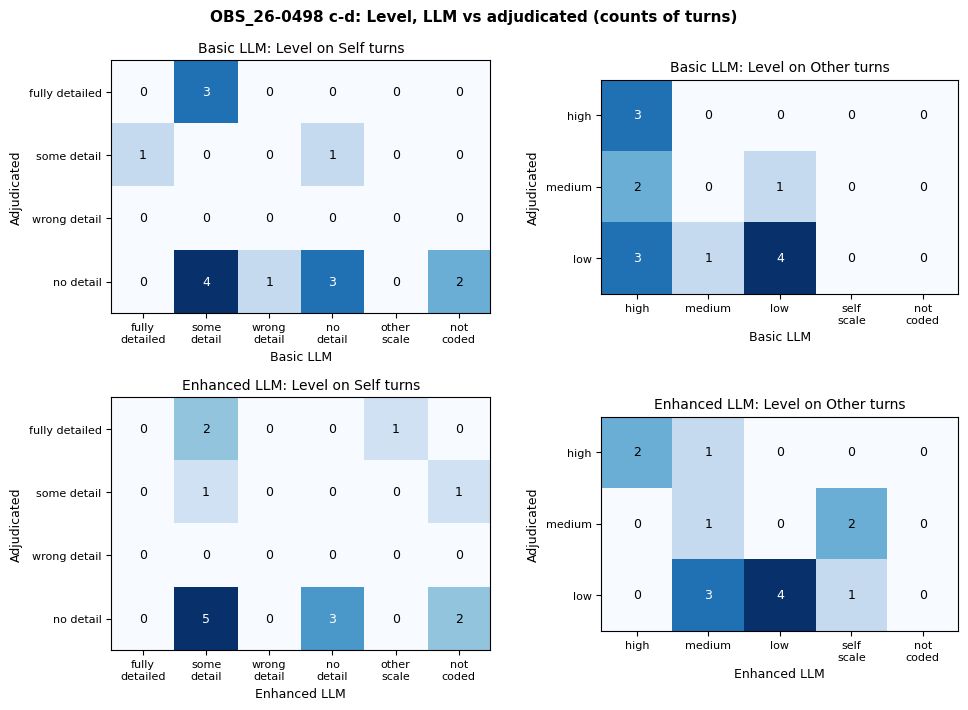

In [11]:
def scale_map(own_levels, other_levels, other_name):
    return lambda label: other_name if label in other_levels else label


level_panels = [
    ("self", SELF_LEVELS, SELF_LEVELS + ["other scale", "not coded"], scale_map(SELF_LEVELS, OTHER_LEVELS, "other scale")),
    ("other", OTHER_LEVELS, OTHER_LEVELS + ["self scale", "not coded"], scale_map(OTHER_LEVELS, SELF_LEVELS, "self scale")),
]

figure, axes = plt.subplots(2, 2, figsize=(10, 7.2), gridspec_kw={"width_ratios": [6, 5]})
level_counts = {}

for row, rater in enumerate(["Basic LLM", "Enhanced LLM"]):
    turns = adjudicated[(adjudicated["rater"] == rater) & (adjudicated["reference_level"] != "")]
    for column, (whose, row_labels, column_labels, column_map) in enumerate(level_panels):
        subset = with_values(turns[turns["reference_whose"] == whose], "level")
        counts = confusion(subset, row_labels, column_labels, column_map)
        level_counts[(rater, whose)] = counts
        plot_confusion(axes[row, column], counts, f"{rater}: Level on {whose.capitalize()} turns",
                       rater, "Adjudicated")

figure.suptitle("OBS_26-0498 c-d: Level, LLM vs adjudicated (counts of turns)", fontsize=11, weight="bold")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "confusion_level.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Disagreement cases

Turns where the enhanced prompt differs from the adjudicated codes on Whose or Level, with the basic prompt's label for the same turn. Row IDs join back to the transcript for the qualitative reading.

In [12]:
paired = (
    adjudicated[adjudicated["rater"] == "Enhanced LLM"]
    .merge(adjudicated[adjudicated["rater"] == "Basic LLM"][["turn", "rater_level"]],
           on="turn", suffixes=("", "_basic"))
)


def code_text(whose, level):
    whose = whose or "not coded"
    return f"{whose} / {level}" if level else whose


paired["Adjudicated"] = [code_text(w, l) for w, l in zip(paired["reference_whose"], paired["reference_level"])]
paired["Enhanced LLM"] = [code_text(w, l) for w, l in zip(paired["rater_whose"], paired["rater_level"])]
paired["Basic LLM level"] = paired["rater_level_basic"].replace("", "not coded")
paired["Difference"] = np.select(
    [paired["rater_whose"] == "",
     paired["reference_whose"] != paired["rater_whose"],
     (paired["reference_level"] != "") & (paired["reference_level"] != paired["rater_level"])],
    ["Not coded by LLM", "Whose", "Level"],
    default="",
)

disagreements = (
    paired[paired["Difference"] != ""]
    [["turn", "speaker", "Adjudicated", "Enhanced LLM", "Basic LLM level", "Difference"]]
    .rename(columns={"turn": "Turn", "speaker": "Speaker"})
    .reset_index(drop=True)
)
disagreements.to_csv(OUTPUT_DIR / "disagreements_enhanced_vs_adjudicated.csv", index=False)

save_table_image(
    disagreements,
    OUTPUT_DIR / "disagreements_enhanced_vs_adjudicated.png",
    f"OBS_26-0498 c-d: {len(disagreements)} of {len(paired)} adjudicated turns where the enhanced LLM differs",
)
disagreements

,Turn,Speaker,Adjudicated,Enhanced LLM,Basic LLM level,Difference
0,c5,Other,self / no detail,self / some detail,some detail,Level
1,c10,Gregorio,other / low,other / medium,high,Level
2,c11,Other,other / medium,self / some detail,high,Whose
3,c16,Gregorio,other / low,other / medium,high,Level
4,c17,Other,other / low,other / medium,high,Level
5,c23,Gregorio,self / no detail,not coded,no detail,Not coded by LLM
6,c24,Miguel,other / low,self / some detail,medium,Whose
7,c28,Gregorio,other / high,other / medium,high,Level
8,c39,Other,self / no detail,not coded,not coded,Not coded by LLM
9,c38-c45,Gregorio,self / fully detailed,other / high,some detail,Whose


## Outputs

All files are in `results/llm_agreement/` and contain codes and counts only, no transcript text.

| File | Contents |
|---|---|
| `turn_comparison.csv` | Every reference turn with the reference and rater codes, for every comparison |
| `agreement_summary.csv` | All counts, agreement rates, and κ values |
| `agreement_table.csv`, `agreement_table.png` | The readable agreement table |
| `agreement_bars.png` | Agreement with each human reference, test sample |
| `confusion_whose.png` | Whose confusion matrix, enhanced LLM vs adjudicated |
| `confusion_level.png` | Level confusion matrices, both prompts vs adjudicated |
| `disagreements_enhanced_vs_adjudicated.csv`, `.png` | Turns where the enhanced LLM differs from the adjudicated codes |